# Predicting Used Vehicle Prices on Craigslist
This notebook compares a baseline, Ridge regression and Random Forest regression for predicting listed vehicle prices. Run notebooks 01 and 02 first so the 30,000-row sample exists.

In [1]:
#cell 1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

## 1. Load data and filter prices
Load the 30,000-row sample and remove listings priced below $500 or above $100,000. These are likely placeholder prices, scrap vehicles or rare luxury vehicles that are not representative of typical listings.

In [2]:
#cell 2
# Load working sample
df = pd.read_csv("../data/processed/craigslist_30k_sample.csv")

# Filter target outliers
df_clean = df[
    (df['price'] >= 500) &
    (df['price'] <= 100000)
].copy()

print(f"Original rows: {len(df)}")
print(f"Rows remaining after price filtering: {len(df_clean)}")
print(f"Rows dropped: {len(df) - len(df_clean)}")

Original rows: 30000
Rows remaining after price filtering: 26974
Rows dropped: 3026


## 2. Feature engineering
Create `vehicle_age` (2021 minus model year, since the data was scraped in 2021) and `miles_per_year`. Age is clipped at zero before adding one to avoid division by zero. Select the numerical and categorical input features.

In [3]:
#cell 3
# Feature engineering
dataset_year = 2021

df_clean['vehicle_age'] = dataset_year - df_clean['year']

df_clean['miles_per_year'] = (
    df_clean['odometer'] /
    (df_clean['vehicle_age'].clip(lower=0) + 1)
)

# Define numerical and categorical features
num_features = [
    'odometer',
    'vehicle_age',
    'miles_per_year'
]

cat_features = [
    'manufacturer',
    'fuel',
    'title_status',
    'transmission',
    'drive',
    'type',
    'state'
]

# Define input features and target
X = df_clean[num_features + cat_features]
y = df_clean['price']

print(f"Number of input features: {X.shape[1]}")
print(f"Number of observations: {X.shape[0]}")

Number of input features: 10
Number of observations: 26974


## 3. Train/test split
Split the data 80/20 with `random_state=42`. The test set is not used for any modelling decisions and is only evaluated once at the end.

In [4]:
#cell 4
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(f"Training observations: {len(X_train)}")
print(f"Test observations: {len(X_test)}")

Training observations: 21579
Test observations: 5395


## 4. Preprocessing pipeline
Numerical features are median-imputed and scaled. Categorical features are imputed with the most frequent value and one-hot encoded. Preprocessing is placed inside each model's pipeline so it is fitted only on the training data in each cross-validation fold, which prevents data leakage.

In [5]:
#cell 5
# Numerical preprocessing
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_features),
    ('cat', cat_pipeline, cat_features)
])

## 5. Models
Define three models: a Dummy baseline that predicts the median price, Ridge regression with the regularisation strength chosen by cross-validation (`RidgeCV`), and a Random Forest with default-style settings.

In [6]:
#cell 6
# Dummy baseline
dummy_model = Pipeline([
    ('prep', preprocessor),
    ('regressor', DummyRegressor(strategy='median'))
])

# Ridge regression
ridge_model = Pipeline([
    ('prep', preprocessor),
    ('regressor', RidgeCV(alphas=np.logspace(-2, 3, 10)))
])

# Random Forest
random_forest_model = Pipeline([
    ('prep', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=100,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

## 6. Cross-validation
Compare the models with 5-fold cross-validation on the training set using RMSE, MAE and R². The standard deviation across folds is reported for RMSE to show how consistent each model is.

In [7]:
#cell 7
# Define cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring = {
    'rmse': 'neg_root_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
    'r2': 'r2'
}

# Evaluate Dummy baseline
dummy_cv = cross_validate(
    dummy_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Evaluate Ridge
ridge_cv = cross_validate(
    ridge_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Evaluate Random Forest
random_forest_cv = cross_validate(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Display results
print("--- 5-Fold Cross-Validation Results ---")

for name, result in [
    ("Dummy", dummy_cv),
    ("Ridge", ridge_cv),
    ("Random Forest", random_forest_cv)
]:
    print(f"\n{name}")
    print(f"RMSE: ${-result['test_rmse'].mean():,.2f} "
          f"(± ${result['test_rmse'].std():,.2f})")
    print(f"MAE:  ${-result['test_mae'].mean():,.2f}")
    print(f"R2:   {result['test_r2'].mean():.4f}")

--- 5-Fold Cross-Validation Results ---

Dummy
RMSE: $14,789.17 (± $422.55)
MAE:  $11,171.14
R2:   -0.0547

Ridge
RMSE: $10,958.68 (± $388.21)
MAE:  $7,673.25
R2:   0.4206

Random Forest
RMSE: $7,412.15 (± $302.21)
MAE:  $4,487.05
R2:   0.7348


## 7. Random Forest tuning
Tune `max_depth` and `min_samples_leaf` with grid search and 5-fold cross-validation on the training set only. The best configuration matched the original settings, so tuning produced no meaningful improvement.

In [8]:
#cell 8
# Set up cross-validation
# Define parameter combinations
param_grid = {
    'regressor__max_depth': [None, 20],
    'regressor__min_samples_leaf': [1, 2, 4]
}

# Set up GridSearchCV
rf_tuning = GridSearchCV(
    estimator=random_forest_model,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=1,
    refit=True,
    verbose=1
)

# Run tuning on training data only
rf_tuning.fit(X_train, y_train)

print("\n--- Random Forest Hyperparameter Tuning ---")
print(f"Best parameters: {rf_tuning.best_params_}")
print(f"Best CV RMSE: ${-rf_tuning.best_score_:,.2f}")

# Display all tuning results
tuning_results = pd.DataFrame(rf_tuning.cv_results_)

tuning_results = tuning_results[[
    'param_regressor__max_depth',
    'param_regressor__min_samples_leaf',
    'mean_test_score',
    'std_test_score',
    'rank_test_score'
]].copy()

tuning_results['mean_CV_RMSE'] = -tuning_results['mean_test_score']
tuning_results['std_CV_RMSE'] = tuning_results['std_test_score']

tuning_results = tuning_results.sort_values('rank_test_score')

print("\n--- All Random Forest Tuning Results ---")

print(tuning_results[[
    'param_regressor__max_depth',
    'param_regressor__min_samples_leaf',
    'mean_CV_RMSE',
    'std_CV_RMSE',
    'rank_test_score'
]].to_string(index=False))

Fitting 5 folds for each of 6 candidates, totalling 30 fits

--- Random Forest Hyperparameter Tuning ---
Best parameters: {'regressor__max_depth': None, 'regressor__min_samples_leaf': 1}
Best CV RMSE: $7,412.15

--- All Random Forest Tuning Results ---
param_regressor__max_depth  param_regressor__min_samples_leaf  mean_CV_RMSE  std_CV_RMSE  rank_test_score
                      None                                  1   7412.153644   302.205944                1
                      None                                  2   7448.054712   288.279455                2
                        20                                  1   7490.216569   319.466753                3
                        20                                  2   7506.863438   304.379975                4
                      None                                  4   7628.139356   324.183111                5
                        20                                  4   7654.095185   329.910784                6


## 8. Final test set evaluation
Fit each model on the full training set and evaluate once on the held-out test set.

In [12]:
#cell 9
# Fit and predict using Dummy baseline
dummy_model.fit(X_train, y_train)
dummy_y_pred = dummy_model.predict(X_test)

# Fit and predict using Ridge
ridge_model.fit(X_train, y_train)
ridge_y_pred = ridge_model.predict(X_test)

# Fit and predict using Random Forest
random_forest_model.fit(X_train, y_train)
rf_y_pred = random_forest_model.predict(X_test)

# Display test results
print("--- Final Protected Test Set Evaluation ---")

for name, predictions in [
    ("Dummy", dummy_y_pred),
    ("Ridge", ridge_y_pred),
    ("Random Forest", rf_y_pred)
]:
    print(f"\n{name}")
    print(f"MAE:  ${mean_absolute_error(y_test, predictions):,.2f}")
    print(f"RMSE: ${np.sqrt(mean_squared_error(y_test, predictions)):,.2f}")
    print(f"R2:   {r2_score(y_test, predictions):.4f}")

--- Final Protected Test Set Evaluation ---

Dummy
MAE:  $11,173.76
RMSE: $14,786.23
R2:   -0.0518

Ridge
MAE:  $7,655.73
RMSE: $10,853.60
R2:   0.4333

Random Forest
MAE:  $4,326.87
RMSE: $7,327.59
R2:   0.7417


## 9. Results table
Combined cross-validation and test results for all three models. Similar values between the two suggest the models generalise and are not overfitted to the training data.

In [13]:
#cell 10
results = pd.DataFrame({
    'Model': ['Dummy', 'Ridge', 'Random Forest'],

    'CV RMSE': [
        -dummy_cv['test_rmse'].mean(),
        -ridge_cv['test_rmse'].mean(),
        -random_forest_cv['test_rmse'].mean()
    ],

    'CV RMSE Std': [
        dummy_cv['test_rmse'].std(),
        ridge_cv['test_rmse'].std(),
        random_forest_cv['test_rmse'].std()
    ],

    'CV MAE': [
        -dummy_cv['test_mae'].mean(),
        -ridge_cv['test_mae'].mean(),
        -random_forest_cv['test_mae'].mean()
    ],

    'CV R2': [
        dummy_cv['test_r2'].mean(),
        ridge_cv['test_r2'].mean(),
        random_forest_cv['test_r2'].mean()
    ],

    'Test RMSE': [
        np.sqrt(mean_squared_error(y_test, dummy_y_pred)),
        np.sqrt(mean_squared_error(y_test, ridge_y_pred)),
        np.sqrt(mean_squared_error(y_test, rf_y_pred))
    ],

    'Test MAE': [
        mean_absolute_error(y_test, dummy_y_pred),
        mean_absolute_error(y_test, ridge_y_pred),
        mean_absolute_error(y_test, rf_y_pred)
    ],

    'Test R2': [
        r2_score(y_test, dummy_y_pred),
        r2_score(y_test, ridge_y_pred),
        r2_score(y_test, rf_y_pred)
    ]
})

print("--- Final Model Comparison ---")
print(results.round(4).to_string(index=False))

--- Final Model Comparison ---
        Model    CV RMSE  CV RMSE Std     CV MAE   CV R2  Test RMSE   Test MAE  Test R2
        Dummy 14789.1732     422.5478 11171.1358 -0.0547 14786.2273 11173.7637  -0.0518
        Ridge 10958.6792     388.2102  7673.2535  0.4206 10853.5998  7655.7307   0.4333
Random Forest  7412.1536     302.2059  4487.0510  0.7348  7327.5853  4326.8712   0.7417


## 10. Residual analysis
Plot residuals (actual minus predicted) against predicted price for Ridge and Random Forest to show where errors occur.

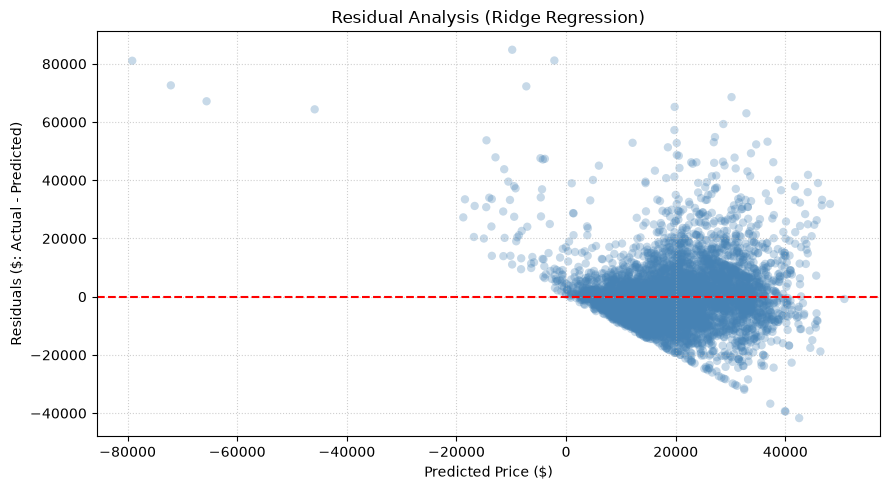

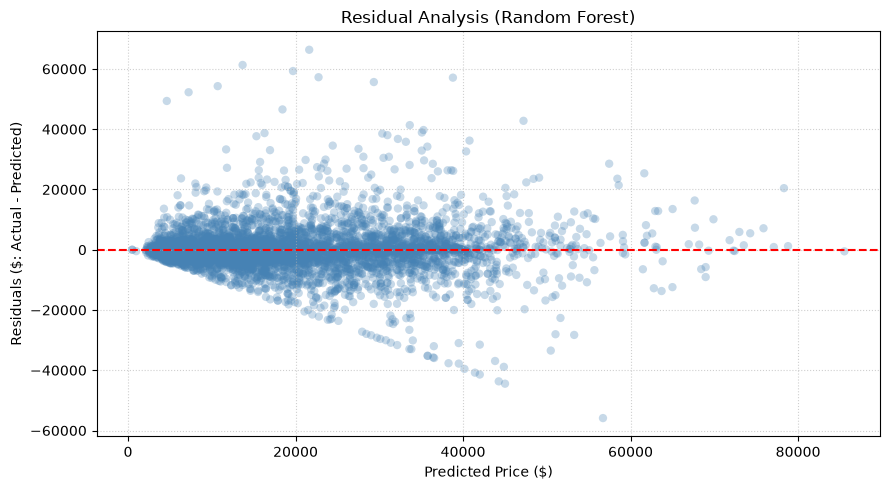

In [14]:
#cell 11
# Ridge residual analysis
residuals = y_test - ridge_y_pred

plt.figure(figsize=(9, 5))
plt.scatter(
    ridge_y_pred,
    residuals,
    alpha=0.3,
    color='steelblue',
    edgecolor='none'
)
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.xlabel("Predicted Price ($)")
plt.ylabel("Residuals ($: Actual - Predicted)")
plt.title("Residual Analysis (Ridge Regression)")
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


# Random Forest residual analysis
rf_residuals = y_test - rf_y_pred

plt.figure(figsize=(9, 5))
plt.scatter(
    rf_y_pred,
    rf_residuals,
    alpha=0.3,
    color='steelblue',
    edgecolor='none'
)
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.xlabel("Predicted Price ($)")
plt.ylabel("Residuals ($: Actual - Predicted)")
plt.title("Residual Analysis (Random Forest)")
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## 11. Ridge coefficients
Largest Ridge coefficients after scaling. Note that rare manufacturers such as Ferrari and Aston Martin dominate, which reflects very few listings rather than reliable pricing effects.

In [15]:
#cell 12
# Extract feature names from fitted ColumnTransformer
feature_names = ridge_model.named_steps['prep'].get_feature_names_out()

# Extract fitted Ridge coefficients
coefficients = ridge_model.named_steps['regressor'].coef_

# Create DataFrame of coefficients
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

# Sort by absolute coefficient magnitude
coef_df['Abs_Coef'] = coef_df['Coefficient'].abs()

coef_df = (
    coef_df
    .sort_values(by='Abs_Coef', ascending=False)
    .drop(columns='Abs_Coef')
)

print("--- Top 15 Most Influential Ridge Features ---")
print(coef_df.head(15).to_string(index=False))

--- Top 15 Most Influential Ridge Features ---
                       Feature   Coefficient
     cat__manufacturer_ferrari  69059.150754
cat__manufacturer_aston-martin -30334.778778
       cat__manufacturer_tesla  14728.247462
      cat__manufacturer_datsun  14178.916991
     cat__manufacturer_porsche  10155.603215
              cat__fuel_diesel   9351.984784
  cat__manufacturer_land rover  -9151.145448
      cat__manufacturer_saturn  -8336.813339
        cat__manufacturer_fiat  -8222.165857
  cat__manufacturer_mitsubishi  -7522.757817
       cat__manufacturer_rover   7459.059720
     cat__title_status_missing   6932.035784
                 cat__type_bus  -6478.009643
       cat__manufacturer_mazda  -6319.101084
         cat__manufacturer_kia  -6168.895244


## 12. Error by price band
Group test listings by actual price and compare MAE and median percentage error for Ridge and Random Forest. Bands use actual prices for analysis only, not for prediction.

In [16]:
# Error analysis by price band (test set only)

# Put actual prices and both models' predictions side by side
band_df = pd.DataFrame({
    'actual': y_test.values,
    'ridge_pred': ridge_y_pred,
    'rf_pred': rf_y_pred
})

# Absolute error in dollars
band_df['ridge_abs_err'] = (band_df['actual'] - band_df['ridge_pred']).abs()
band_df['rf_abs_err'] = (band_df['actual'] - band_df['rf_pred']).abs()

# Absolute error as a percentage of the actual price
band_df['ridge_pct_err'] = band_df['ridge_abs_err'] / band_df['actual'] * 100
band_df['rf_pct_err'] = band_df['rf_abs_err'] / band_df['actual'] * 100

# Group cars into price bands based on their actual price
bins = [500, 5000, 10000, 20000, 40000, 100000]
labels = ['$500-5k', '$5k-10k', '$10k-20k', '$20k-40k', '$40k-100k']
band_df['price_band'] = pd.cut(
    band_df['actual'], bins=bins, labels=labels, include_lowest=True
)

# Summarise each band
band_summary = band_df.groupby('price_band', observed=True).agg(
    n_cars=('actual', 'count'),
    ridge_MAE=('ridge_abs_err', 'mean'),
    rf_MAE=('rf_abs_err', 'mean'),
    ridge_median_pct_err=('ridge_pct_err', 'median'),
    rf_median_pct_err=('rf_pct_err', 'median')
)

print("--- Test Set Error by Price Band ---")
print(band_summary.round(1).to_string())

--- Test Set Error by Price Band ---
            n_cars  ridge_MAE   rf_MAE  ridge_median_pct_err  rf_median_pct_err
price_band                                                                     
$500-5k        749     8748.2   4401.2                 218.2               63.9
$5k-10k       1137     6357.8   2773.2                  76.9               21.3
$10k-20k      1457     5282.1   3527.0                  27.2               16.7
$20k-40k      1652     6547.4   4372.0                  18.8                9.6
$40k-100k      400    22522.6  11331.2                  39.5               15.4


## 13. Permutation importance
Measure how much Random Forest test RMSE increases when each original feature is shuffled. This shows which inputs the model relies on. Correlated features such as age, odometer and miles per year may share importance.

--- Permutation Importance (increase in test RMSE when shuffled) ---
       Feature  RMSE_increase   Std
   vehicle_age         5054.5 114.6
      odometer         3713.9  69.1
          fuel         2087.1  77.0
         drive         1625.8  61.8
          type         1607.3  59.8
  manufacturer          933.3  41.2
miles_per_year          502.9  15.7
  transmission          434.8  33.1
         state          224.2  20.9
  title_status           73.9  18.2


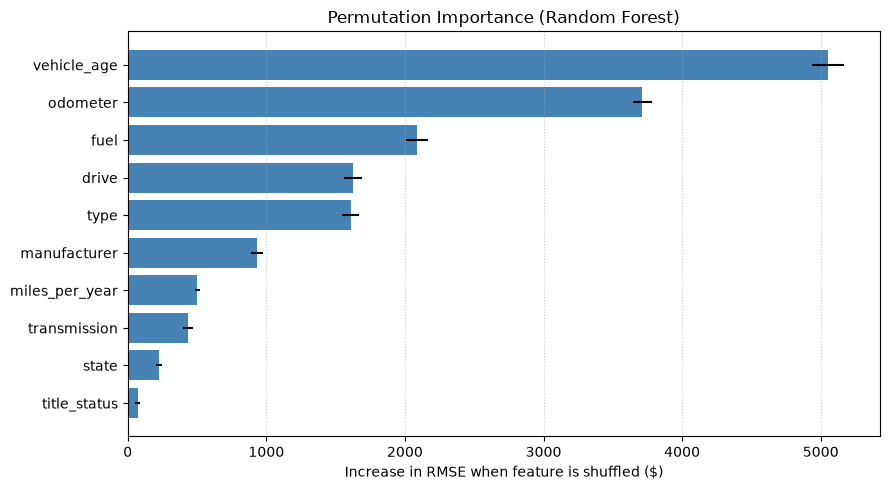

In [17]:
# Permutation feature importance for Random Forest (test set)
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    random_forest_model,           # full pipeline, so we shuffle the ORIGINAL columns
    X_test,
    y_test,
    scoring='neg_root_mean_squared_error',
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'RMSE_increase': perm.importances_mean,
    'Std': perm.importances_std
}).sort_values('RMSE_increase', ascending=False)

print("--- Permutation Importance (increase in test RMSE when shuffled) ---")
print(importance_df.round(1).to_string(index=False))

# Bar chart
plt.figure(figsize=(9, 5))
plt.barh(
    importance_df['Feature'][::-1],
    importance_df['RMSE_increase'][::-1],
    xerr=importance_df['Std'][::-1],
    color='steelblue'
)
plt.xlabel("Increase in RMSE when feature is shuffled ($)")
plt.title("Permutation Importance (Random Forest)")
plt.grid(True, linestyle=':', alpha=0.6, axis='x')
plt.tight_layout()
plt.show()